# SpaceX Falcon 9 — Reproducible Capstone Analysis
**Ckyree Campbell | IBM Applied Data Science Capstone**

**Data provenance:** 56-row historical dashboard sample from the prior evidence package. This is **not** the official API/data-wrangling dataset or your executed course notebook. Sources and limits are explicitly stated. All computations below are executed locally.

## 1. Load and validate evidence

In [1]:
import pandas as pd, numpy as np, sqlite3, matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
P=Path('/mnt/data/SpaceX_IBM_Final_Evidence')
df=pd.read_csv(P/'historical_dash_56.csv')
print('Shape:', df.shape); display(df.head())
assert len(df)==56 and df['FlightNumber'].nunique()==56
assert df['Class'].isin([0,1]).all()
print('Landing success:', int(df.Class.sum()), '/', len(df), '=', round(df.Class.mean()*100,1), '%')

Shape: (56, 5)


,FlightNumber,LaunchSite,Class,PayloadMass,BoosterCategory
0,1,CCAFS LC-40,0,0.0,v1.0
1,2,CCAFS LC-40,0,0.0,v1.0
2,3,CCAFS LC-40,0,525.0,v1.0
3,4,CCAFS LC-40,0,500.0,v1.0
4,5,CCAFS LC-40,0,677.0,v1.0


Landing success: 24 / 56 = 42.9 %


## 2. SQL analysis — ten queries with executed results

In [2]:
con=sqlite3.connect(':memory:');df.to_sql('SPACEXTBL',con,index=False)
q={
'Launch site counts': 'SELECT LaunchSite, COUNT(*) AS Flights FROM SPACEXTBL GROUP BY LaunchSite ORDER BY Flights DESC',
'Site recovery rates':'SELECT LaunchSite, COUNT(*) n, SUM(Class) Successes, ROUND(100*AVG(Class),1) Rate FROM SPACEXTBL GROUP BY LaunchSite ORDER BY Rate DESC',
'Payload by booster':'SELECT BoosterCategory, ROUND(AVG(PayloadMass),1) MeanMass, MAX(PayloadMass) MaxMass FROM SPACEXTBL GROUP BY BoosterCategory',
'Recovery outcome counts':'SELECT Class,COUNT(*) Flights FROM SPACEXTBL GROUP BY Class',
'Top payloads':'SELECT FlightNumber, LaunchSite, PayloadMass FROM SPACEXTBL ORDER BY PayloadMass DESC LIMIT 5',
'CCA prefix':'SELECT FlightNumber, LaunchSite FROM SPACEXTBL WHERE LaunchSite LIKE "CCA%" LIMIT 5',
'Booster recovery rates':'SELECT BoosterCategory, COUNT(*) n, ROUND(100*AVG(Class),1) Rate FROM SPACEXTBL GROUP BY BoosterCategory ORDER BY Rate DESC',
'Payload bands':'SELECT CASE WHEN PayloadMass<2000 THEN "0-1999" WHEN PayloadMass<5000 THEN "2000-4999" ELSE "5000+" END MassBand, COUNT(*) n, ROUND(100*AVG(Class),1) Rate FROM SPACEXTBL GROUP BY MassBand',
'Maximum payload flights':'SELECT FlightNumber,LaunchSite,PayloadMass FROM SPACEXTBL WHERE PayloadMass=(SELECT MAX(PayloadMass) FROM SPACEXTBL)',
'Sites ranked by recovery count':'SELECT LaunchSite,SUM(Class) Successes FROM SPACEXTBL GROUP BY LaunchSite ORDER BY Successes DESC'
}
for name,sql in q.items():
 print('\n###',name,'\n',sql); display(pd.read_sql_query(sql,con))


### Launch site counts 
 SELECT LaunchSite, COUNT(*) AS Flights FROM SPACEXTBL GROUP BY LaunchSite ORDER BY Flights DESC


,LaunchSite,Flights
0,CCAFS LC-40,26
1,KSC LC-39A,13
2,VAFB SLC-4E,10
3,CCAFS SLC-40,7



### Site recovery rates 
 SELECT LaunchSite, COUNT(*) n, SUM(Class) Successes, ROUND(100*AVG(Class),1) Rate FROM SPACEXTBL GROUP BY LaunchSite ORDER BY Rate DESC


,LaunchSite,n,Successes,Rate
0,KSC LC-39A,13,10,76.9
1,CCAFS SLC-40,7,3,42.9
2,VAFB SLC-4E,10,4,40.0
3,CCAFS LC-40,26,7,26.9



### Payload by booster 
 SELECT BoosterCategory, ROUND(AVG(PayloadMass),1) MeanMass, MAX(PayloadMass) MaxMass FROM SPACEXTBL GROUP BY BoosterCategory


...

,MassBand,n,Rate
0,0-1999,13,23.1
1,2000-4999,29,55.2
2,5000+,14,35.7



### Maximum payload flights 
 SELECT FlightNumber,LaunchSite,PayloadMass FROM SPACEXTBL WHERE PayloadMass=(SELECT MAX(PayloadMass) FROM SPACEXTBL)


,FlightNumber,LaunchSite,PayloadMass
0,29,VAFB SLC-4E,9600.0
1,37,VAFB SLC-4E,9600.0
2,42,VAFB SLC-4E,9600.0
3,46,VAFB SLC-4E,9600.0
4,51,VAFB SLC-4E,9600.0



### Sites ranked by recovery count 
 SELECT LaunchSite,SUM(Class) Successes FROM SPACEXTBL GROUP BY LaunchSite ORDER BY Successes DESC


,LaunchSite,Successes
0,KSC LC-39A,10
1,CCAFS LC-40,7
2,VAFB SLC-4E,4
3,CCAFS SLC-40,3


## 3. Exploratory visualizations — actual calculated charts

flight_by_site


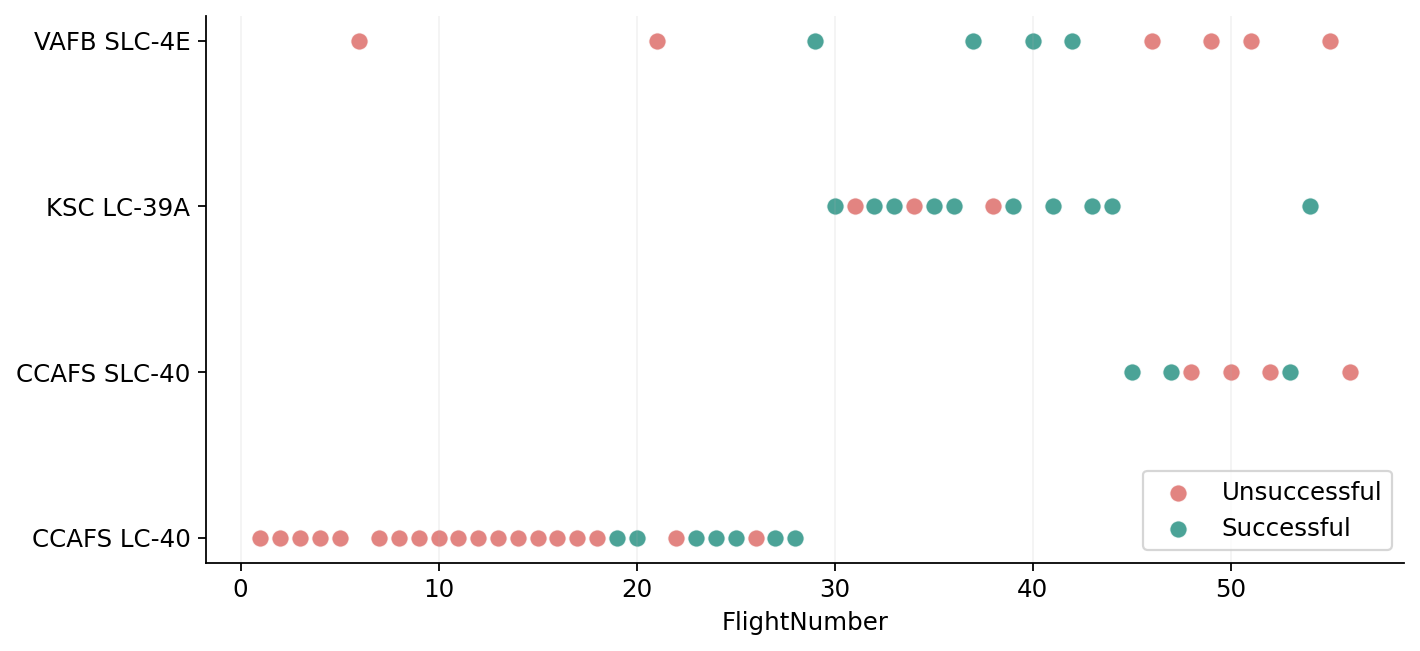

payload_by_site


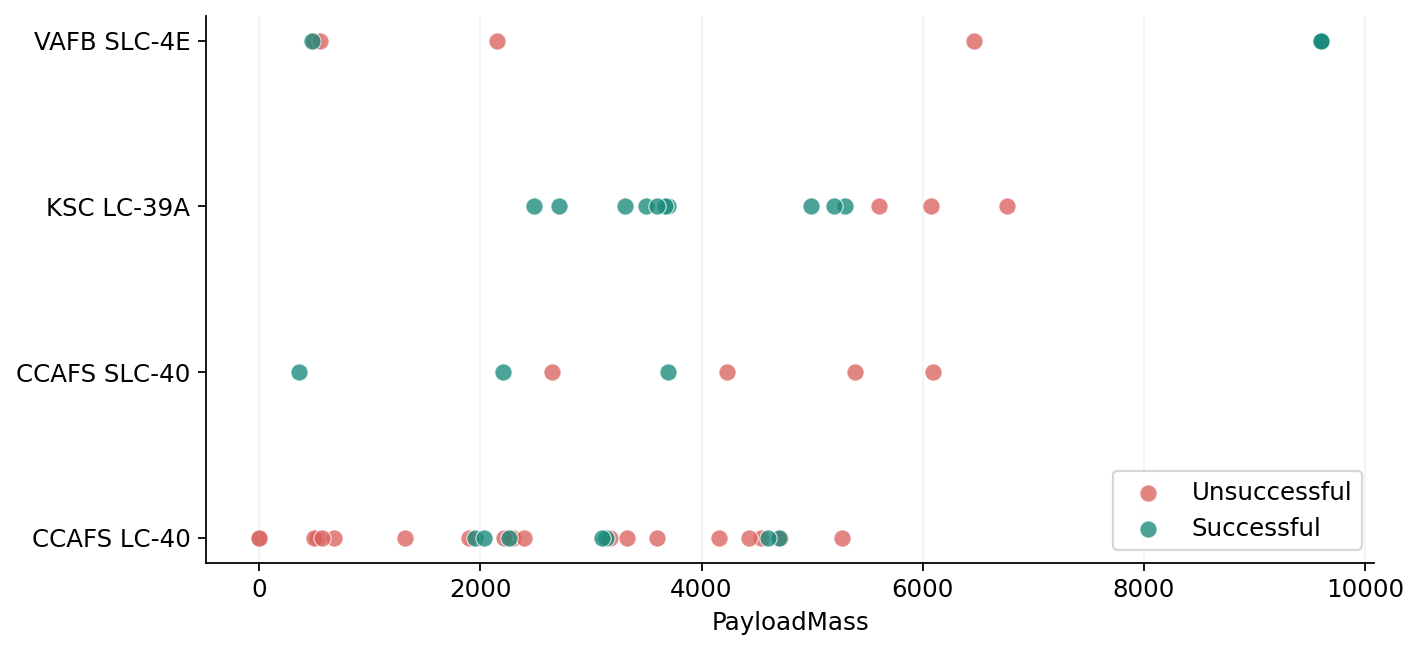

success_by_booster


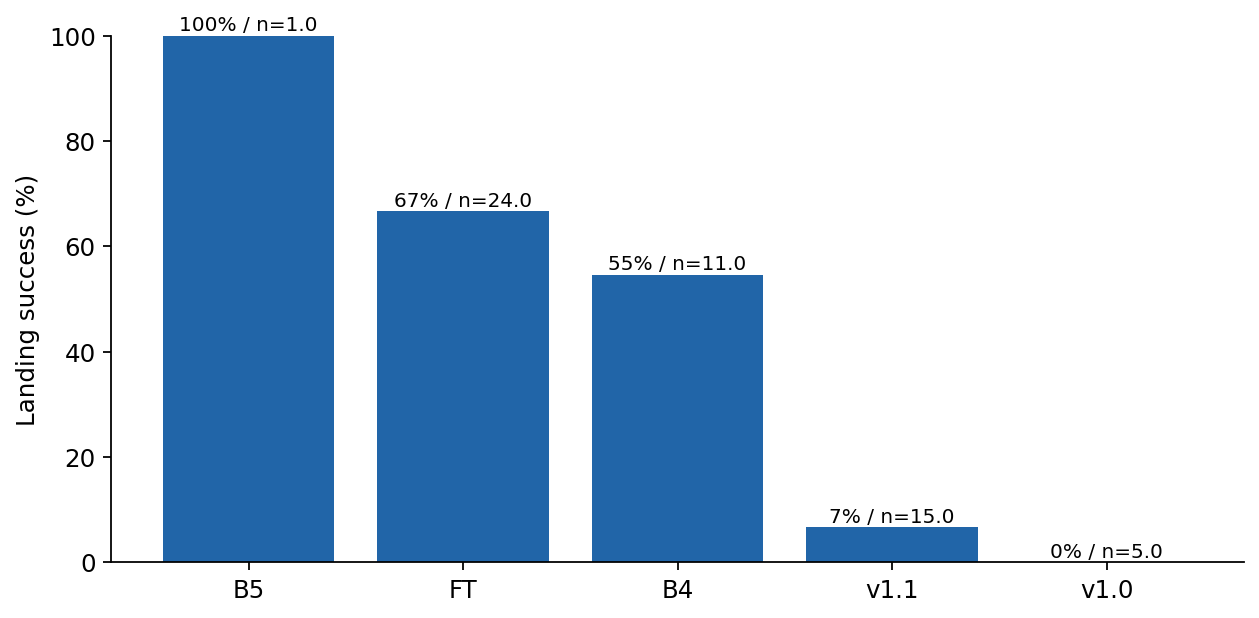

flight_by_booster


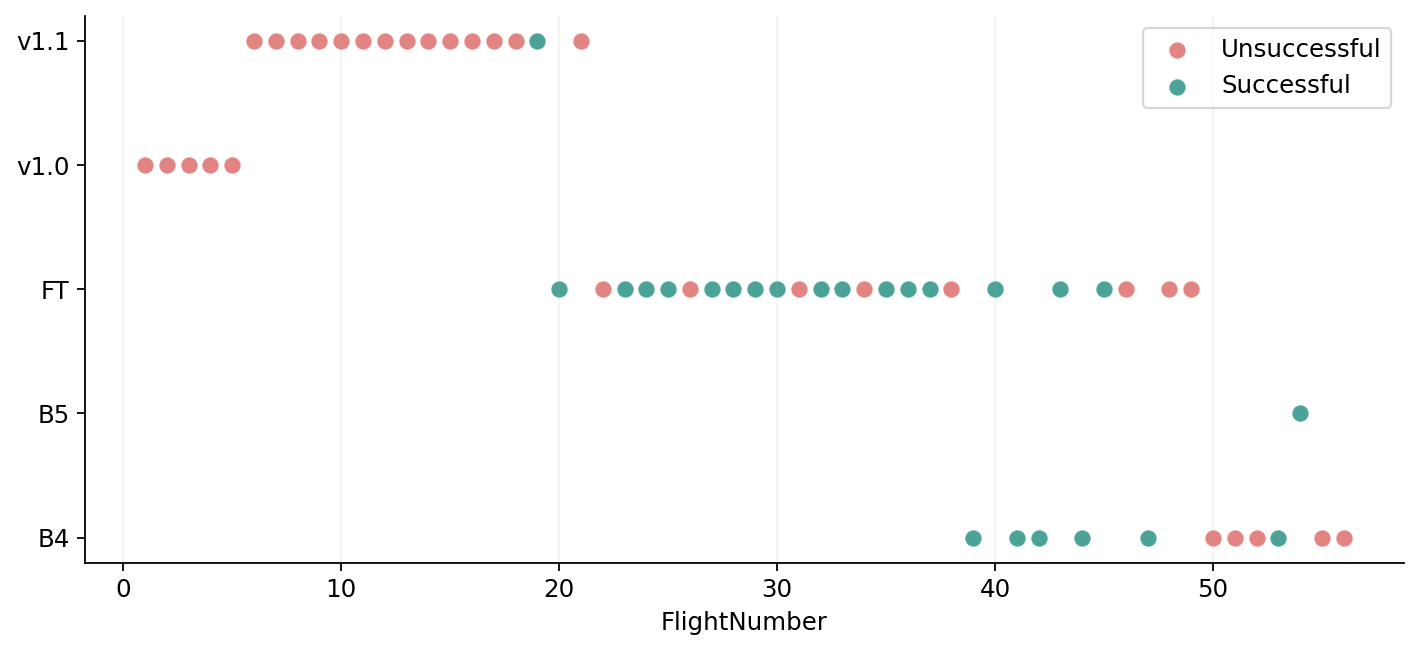

payload_by_booster


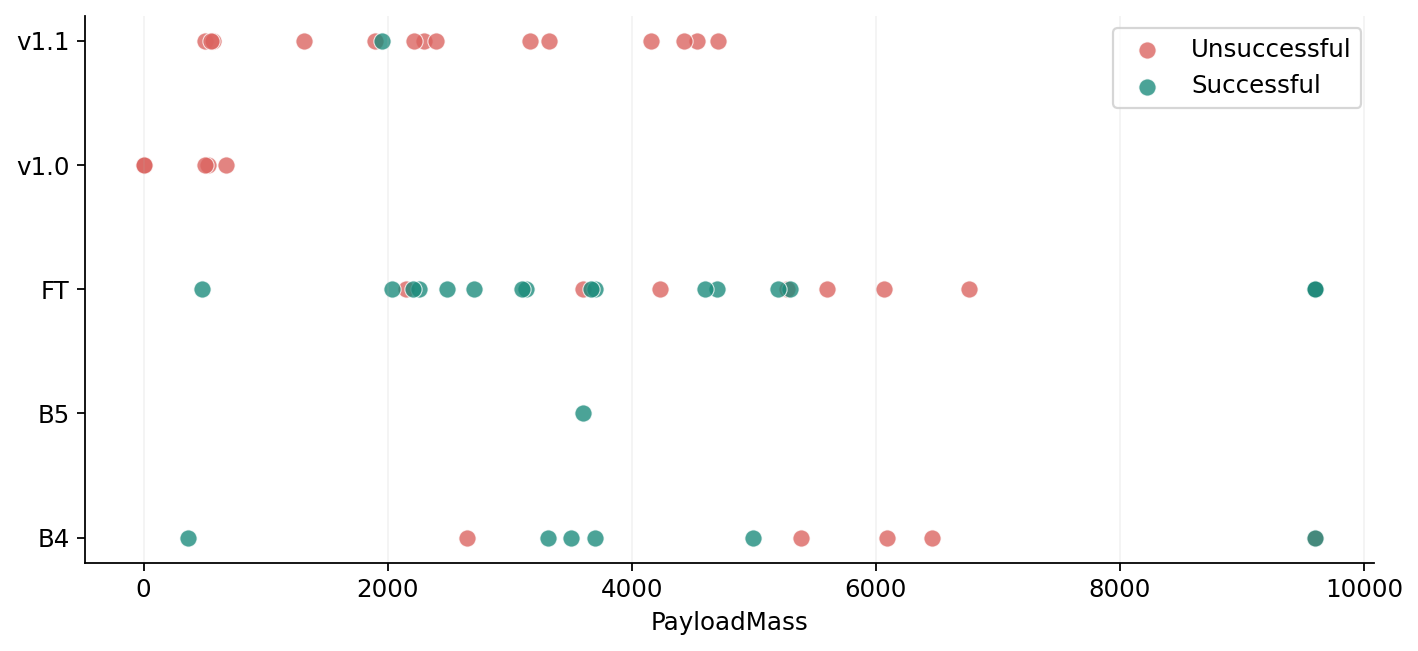

success_by_flight_period


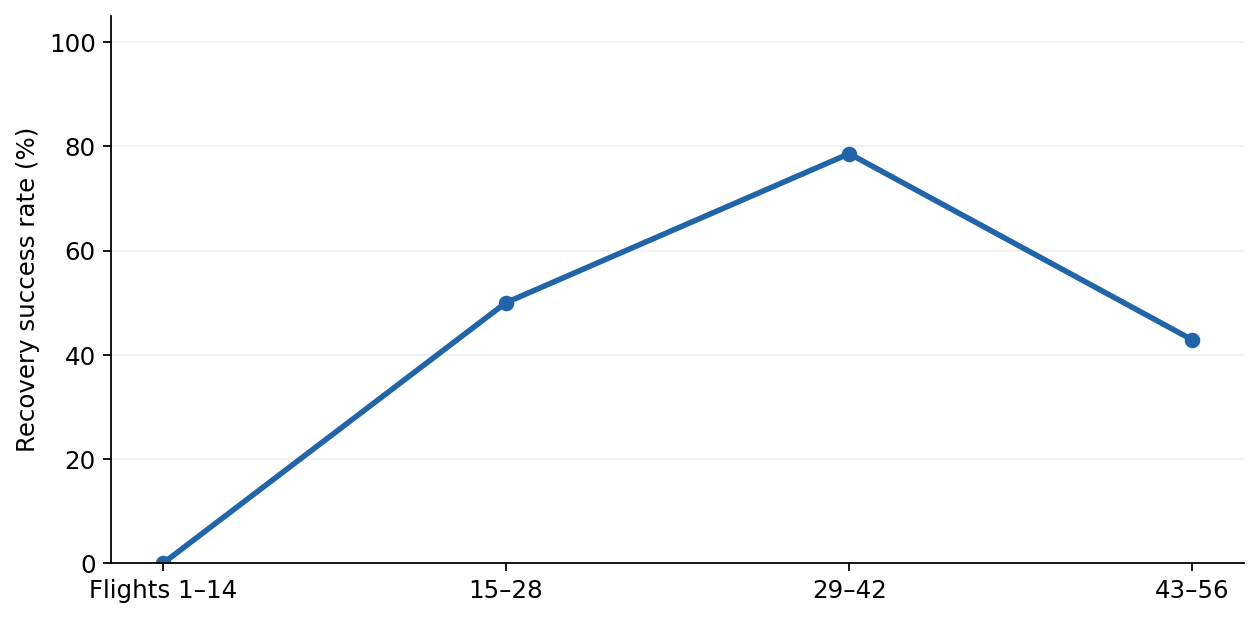

success_by_site


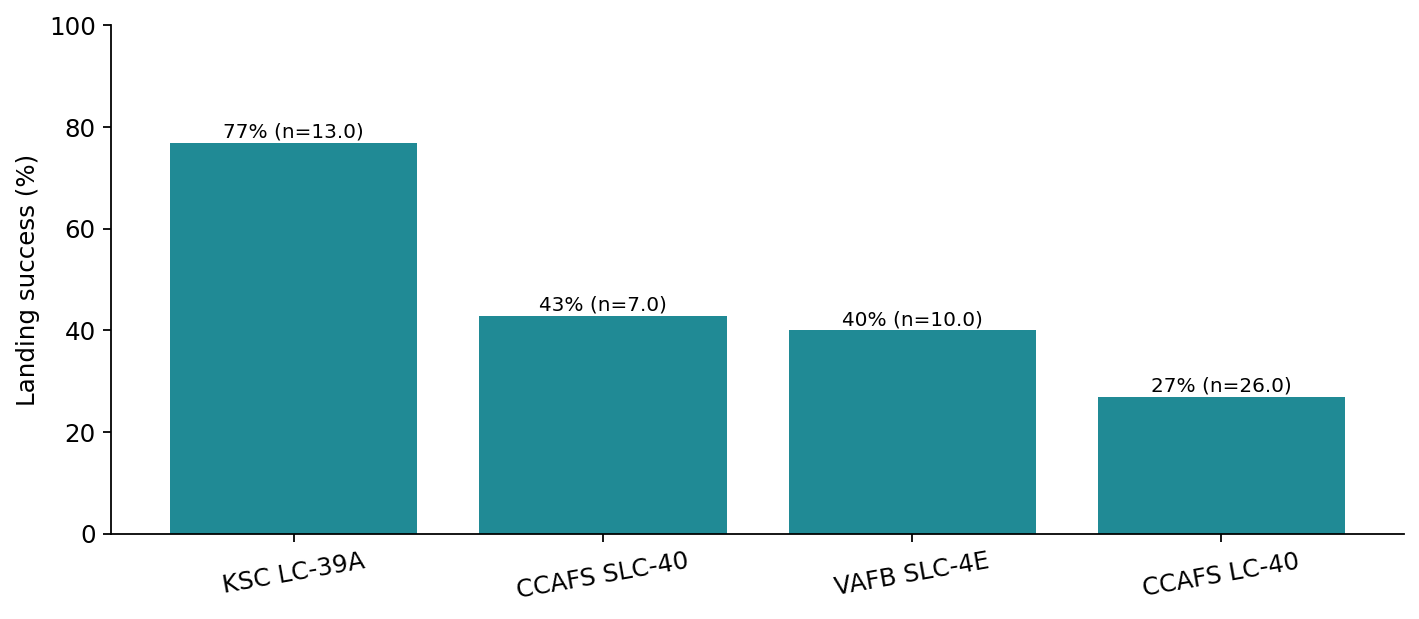

payload_outcome


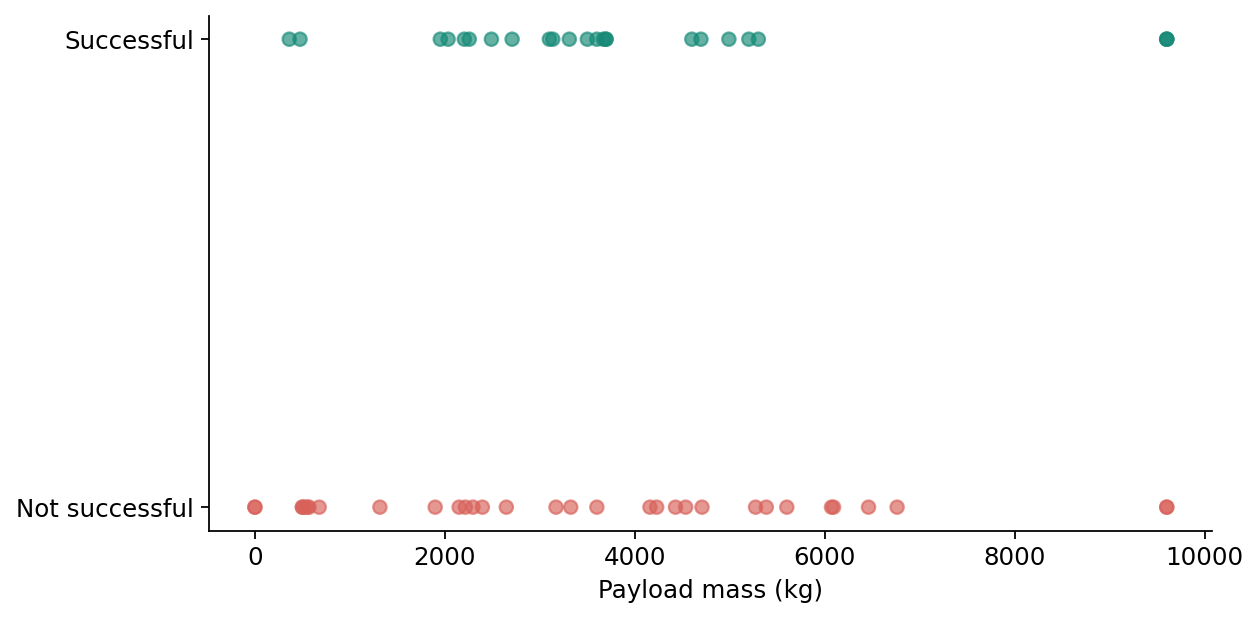

In [3]:
from IPython.display import Image, display
for filename in ['flight_by_site','payload_by_site','success_by_booster','flight_by_booster','payload_by_booster','success_by_flight_period','success_by_site','payload_outcome']:
 print(filename); display(Image(filename=str(P/(filename+'.png')),width=720))

**Limitation:** The course EDA lab calls for orbit and calendar-year analyses. Those fields do **not** occur in the 56-row dashboard source; flight period and booster generation are labeled as substitute analyses, not misrepresented as orbit/year analyses.

## 4. Folium mapping — real generated interactive HTML

Map available at: /mnt/data/SpaceX_IBM_Final_Evidence/folium_site_map.html


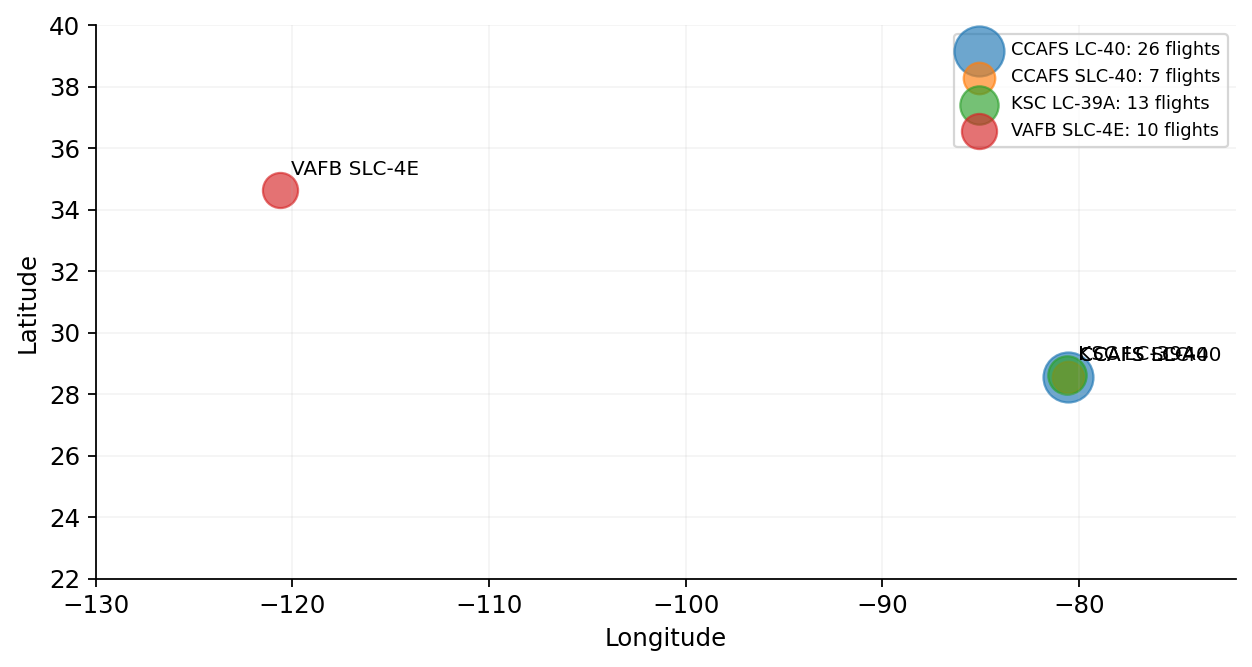

In [4]:
import folium
print('Map available at:',P/'folium_site_map.html')
display(Image(filename=str(P/'map_site_coordinates.png'),width=720))

**Geospatial limitation:** Highway/rail/coastline proximity values cannot be derived reliably from the attached dataset. No distance is invented.

## 5. Machine-learning model results — measured on historical sample

,Model,CV_Accuracy,Test_Accuracy,Parameters
0,SVM,0.786,0.786,"{'model__C': 10, 'model__kernel': 'linear'}"
1,Logistic regression,0.738,0.786,{'model__C': 10}
2,Decision tree,0.738,0.643,"{'max_depth': 3, 'min_samples_leaf': 3}"
3,KNN,0.738,0.571,{'model__n_neighbors': 3}


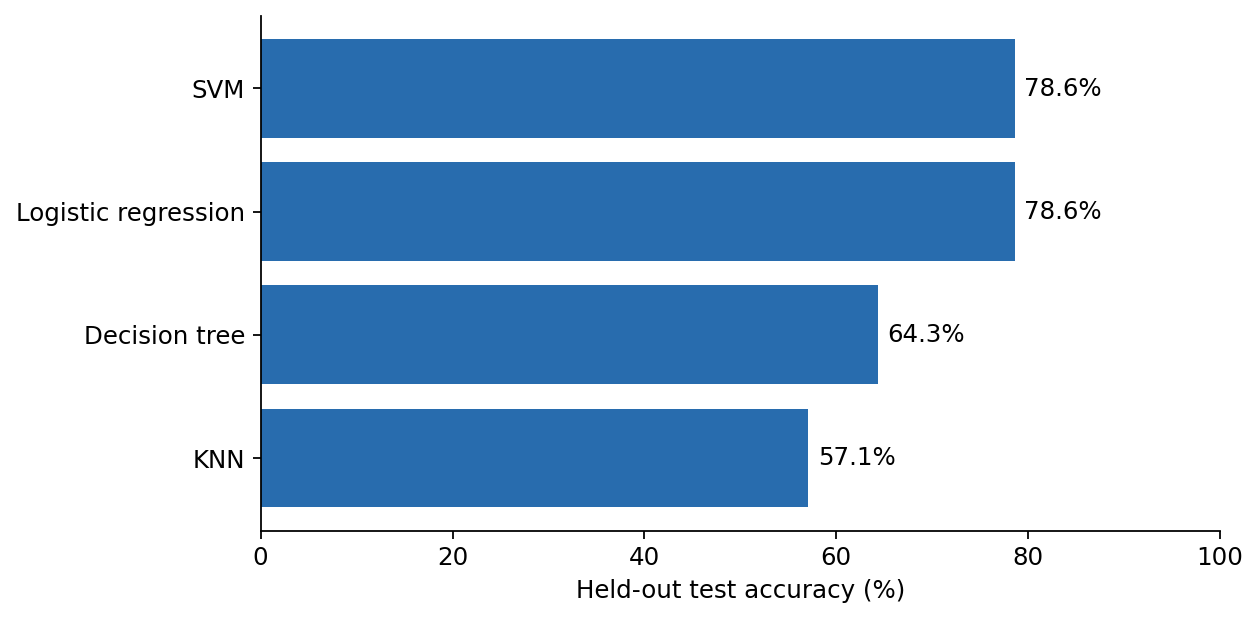

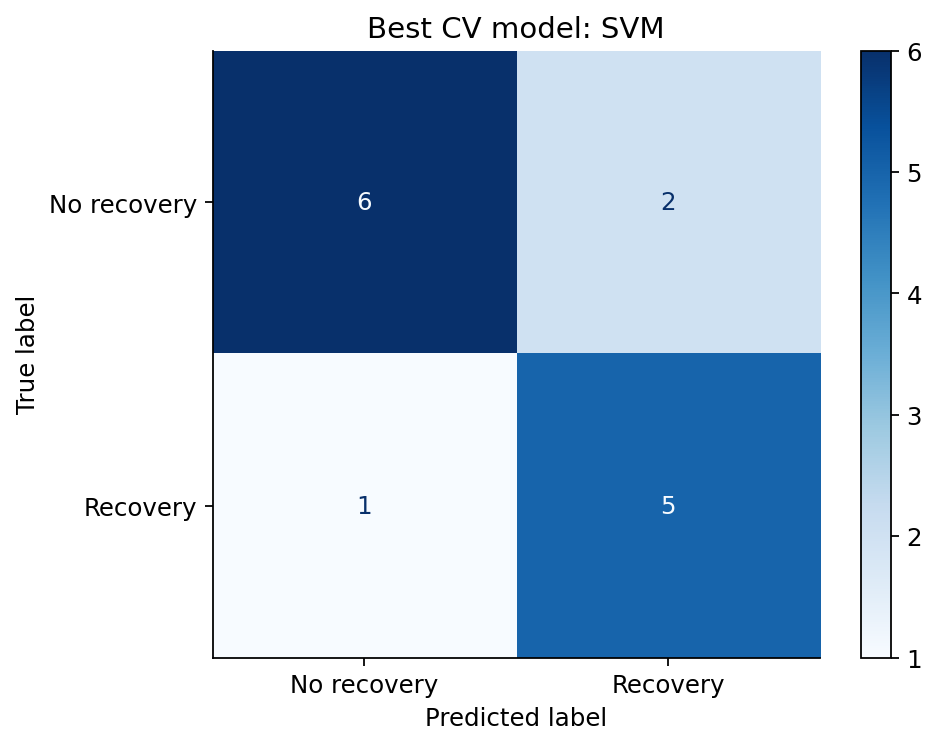

In [5]:
model=pd.read_csv(P/'model_evaluation.csv'); display(model);display(Image(filename=str(P/'model_accuracy.png'),width=720));display(Image(filename=str(P/'model_confusion.png'),width=650))

**Inference limitation:** 56 historical observations and a 14-row holdout set are inadequate for deployment decisions. The machine-learning notebook uploaded with the user’s lab has not been executed on its remote 90-row course data.

## 6. Source and submission checklist

- [x] Historical course-dashboard dataset; executed descriptive SQL, charts and model evaluation.
- [x] Interactive Folium HTML and supplied Dash Python application.
- [ ] Official API / scraper notebook runs with IBM dataset (blocked here by network).
- [ ] Exact orbit and year visualizations from official 90-row dataset.
- [ ] Actual browser screenshots of running Dash.
- [ ] Verified Folium roadway/railway/coastline proximity calculations.
- [ ] Personal public GitHub repository URL.

**This package is an independently executed historical-sample analysis, not a representation that the above unchecked course requirements were completed.**